In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/dormmatch_cleaned.csv")
df.head()

,student_id,age,gender,year_of_study,branch,cgpa,sleep_time,wake_time,sleep_duration,cleanliness_level,...,sharing_preference,weekend_activity,food_habit,smoking_preference,ac_preference,preferred_room_type,budget,preferred_environment,roommate_interaction,calculated_sleep_duration
0,STU0760,19,Female,3,Biotechnology,9.03,2.35,6.71,4.07,3.0,...,3,Outings,Vegetarian,No smoking,Yes,Double,6500.0,Balanced,2,4.36
1,STU1501,21,Male,1,Electrical Engineering,7.92,23.50,6.98,7.31,4.0,...,5,Gaming,Vegetarian,No smoking,Yes,Triple,6500.0,Balanced,4,7.48
2,STU1385,20,Female,4,Computer Science,8.93,22.99,7.18,8.47,5.0,...,3,Movies,non-vegetarian,No smoking,No,Double,6500.0,Social,2,8.19
3,STU0052,20,Male,2,Computer Science,7.45,22.25,5.81,7.90,4.0,...,3,Movies,Eggetarian,No smoking,Yes,Single,5500.0,quiet,4,7.56
4,STU0660,20,Female,2,Electrical Engineering,7.02,0.77,10.68,10.38,2.0,...,5,Relaxing,Non-vegetarian,No preference,Yes,Double,6000.0,Balanced,3,9.91


In [17]:
df.shape, df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 24 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 2000 non-null   object 
 1   age                        2000 non-null   int64  
 2   gender                     2000 non-null   object 
 3   year_of_study              2000 non-null   int64  
 4   branch                     2000 non-null   object 
 5   cgpa                       2000 non-null   float64
 6   sleep_time                 2000 non-null   float64
 7   wake_time                  2000 non-null   float64
 8   sleep_duration             2000 non-null   float64
 9   cleanliness_level          2000 non-null   float64
 10  noise_tolerance            2000 non-null   float64
 11  study_hours                2000 non-null   float64
 12  social_activity            2000 non-null   int64  
 13  introvert_extrovert        2000 non-null   float

((2000, 24), None)

In [18]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,2000,2000,STU0760,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,2000.0,NaN,NaN,NaN,19.8215,1.135466,17.0,19.0,20.0,21.0,24.0
gender,2000,2,Male,1021,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year_of_study,2000.0,NaN,NaN,NaN,2.356,1.08067,1.0,1.0,2.0,3.0,4.0
branch,2000,7,Computer Science,821,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cgpa,2000.0,NaN,NaN,NaN,7.61174,0.987557,4.5,6.97,7.605,8.28,10.0
sleep_time,2000.0,NaN,NaN,NaN,14.54018,10.550918,0.0,1.5975,22.34,23.05,24.0
wake_time,2000.0,NaN,NaN,NaN,7.800545,1.283261,4.4,6.79,7.6,8.74,11.83
sleep_duration,2000.0,NaN,NaN,NaN,7.962885,1.287609,1.0,7.1675,7.91,8.6925,22.0
cleanliness_level,2000.0,NaN,NaN,NaN,3.788,1.028876,1.0,3.0,4.0,5.0,5.0


In [19]:
df.isna().sum().sort_values(ascending=False)

student_id                   0
age                          0
roommate_interaction         0
preferred_environment        0
budget                       0
preferred_room_type          0
ac_preference                0
smoking_preference           0
food_habit                   0
weekend_activity             0
sharing_preference           0
introvert_extrovert          0
social_activity              0
study_hours                  0
noise_tolerance              0
cleanliness_level            0
sleep_duration               0
wake_time                    0
sleep_time                   0
cgpa                         0
branch                       0
year_of_study                0
gender                       0
calculated_sleep_duration    0
dtype: int64

In [20]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()
numeric_cols, categorical_cols

(['age',
  'year_of_study',
  'cgpa',
  'sleep_time',
  'wake_time',
  'sleep_duration',
  'cleanliness_level',
  'noise_tolerance',
  'study_hours',
  'social_activity',
  'introvert_extrovert',
  'sharing_preference',
  'budget',
  'roommate_interaction',
  'calculated_sleep_duration'],
 ['student_id',
  'gender',
  'branch',
  'weekend_activity',
  'food_habit',
  'smoking_preference',
  'ac_preference',
  'preferred_room_type',
  'preferred_environment'])

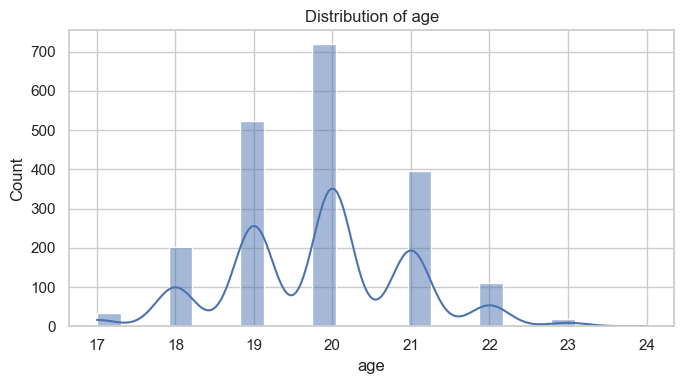

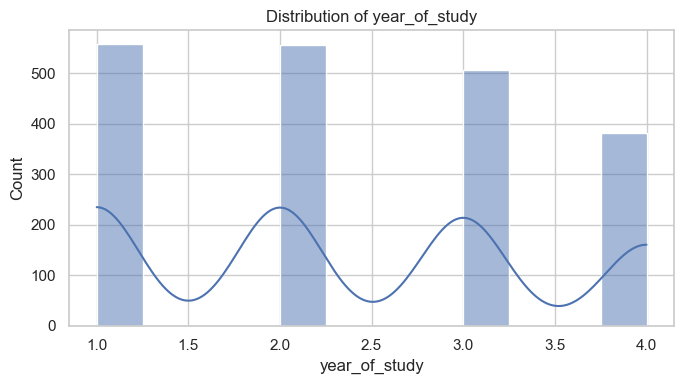

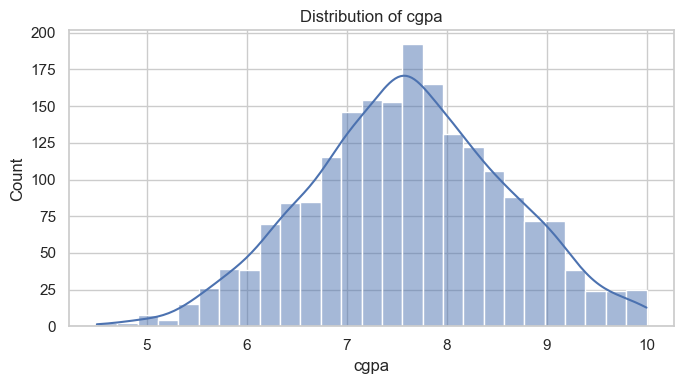

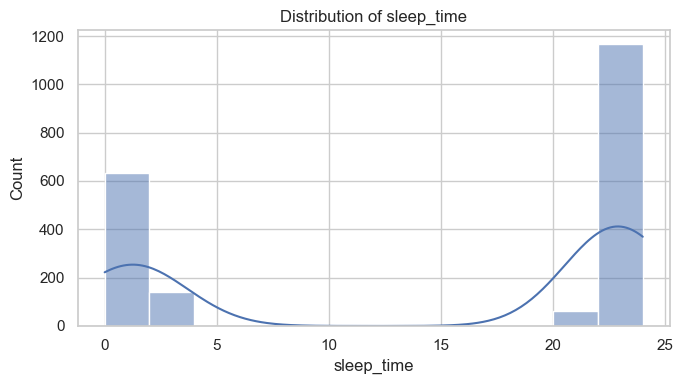

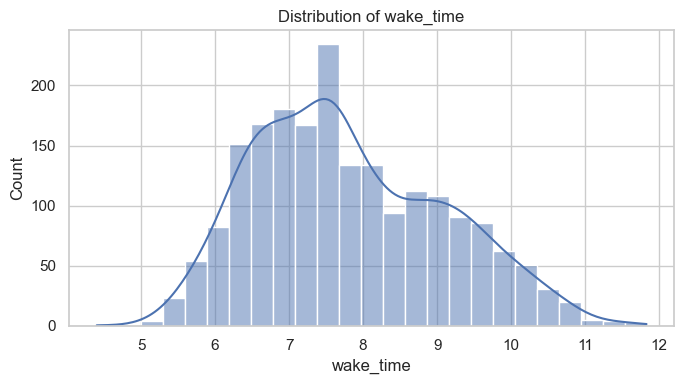

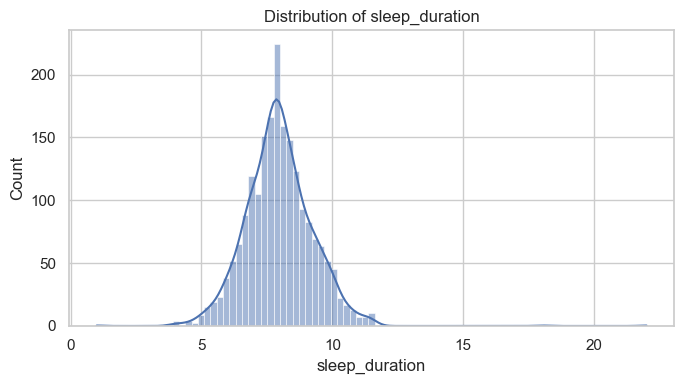

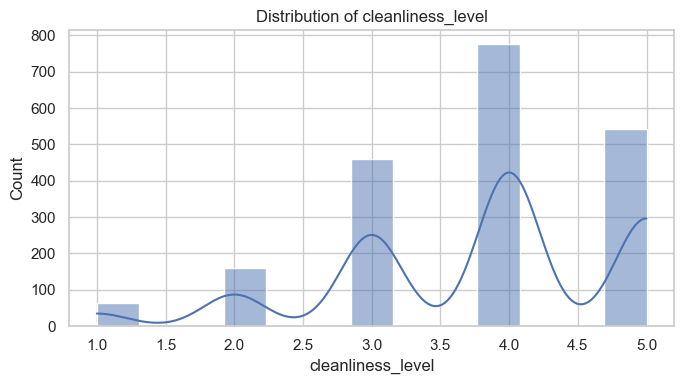

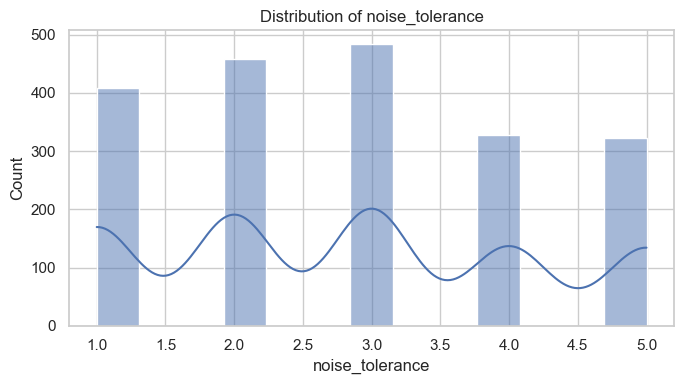

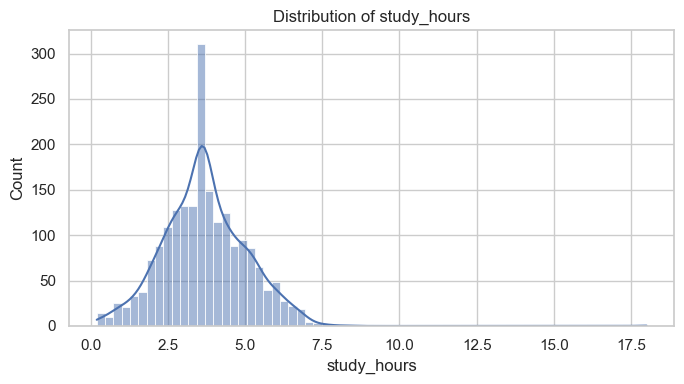

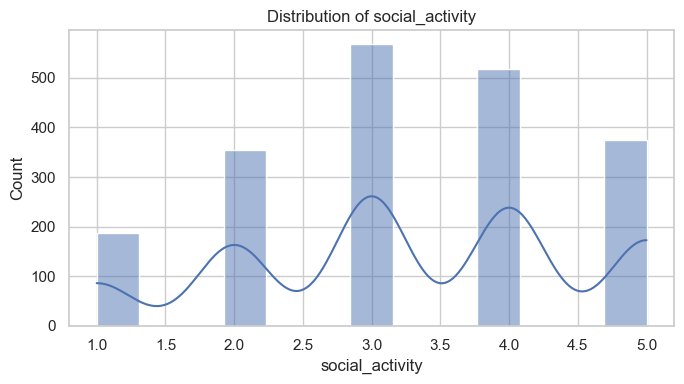

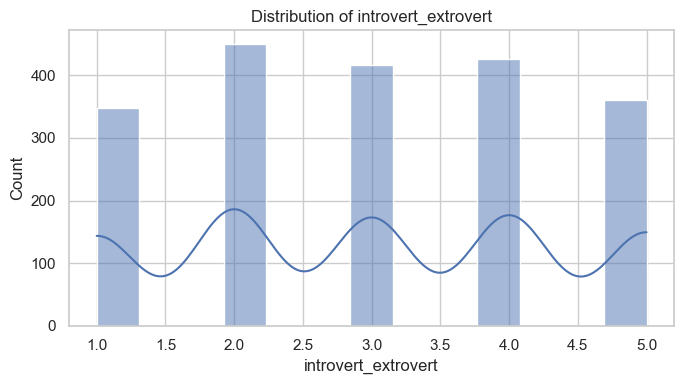

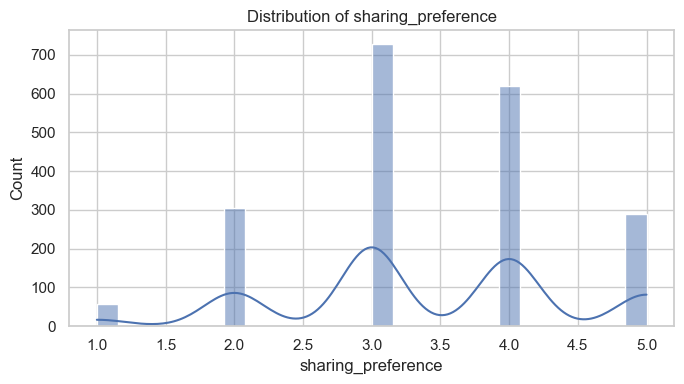

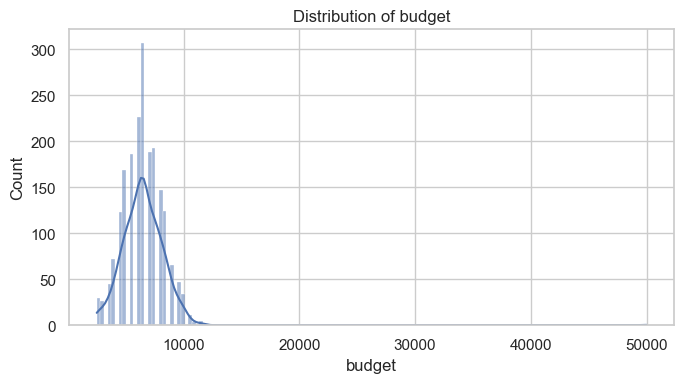

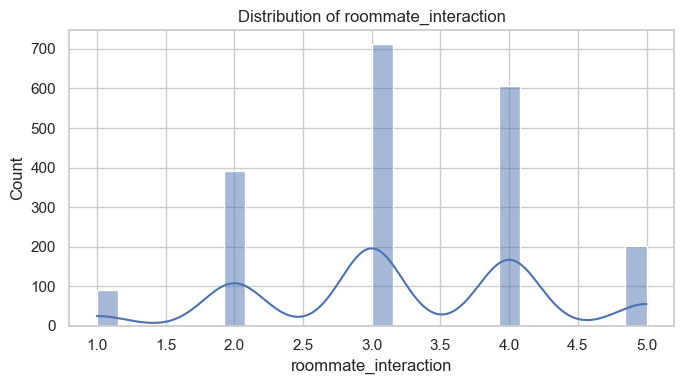

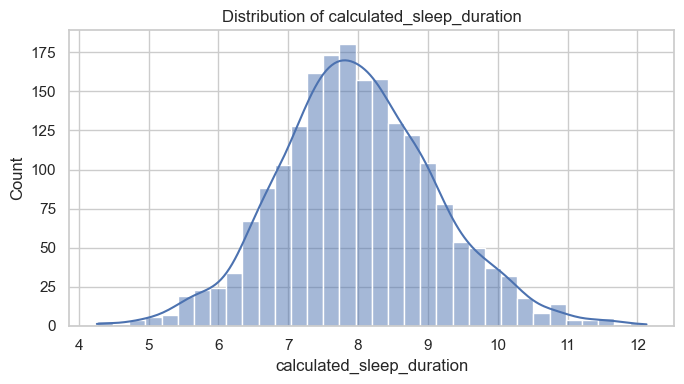

In [21]:
for col in numeric_cols:
    plt.figure(figsize=(7,4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

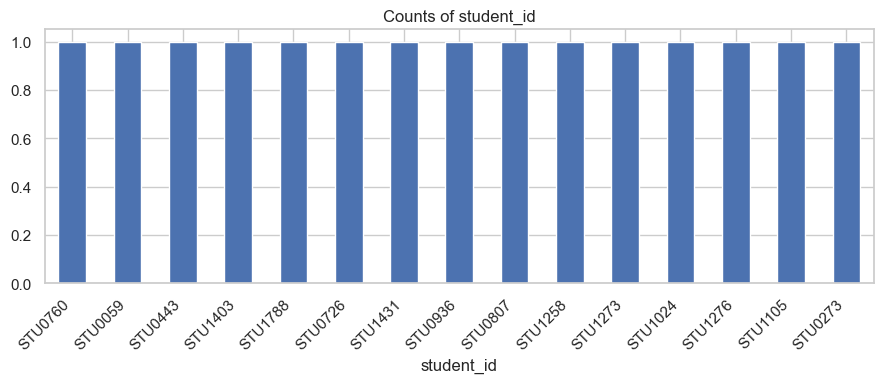

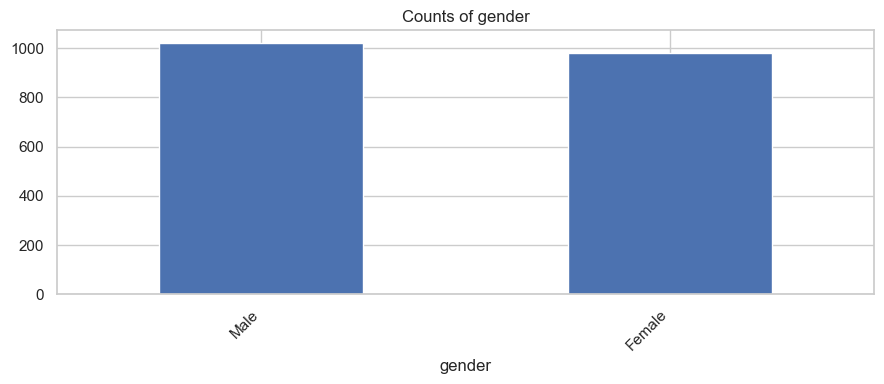

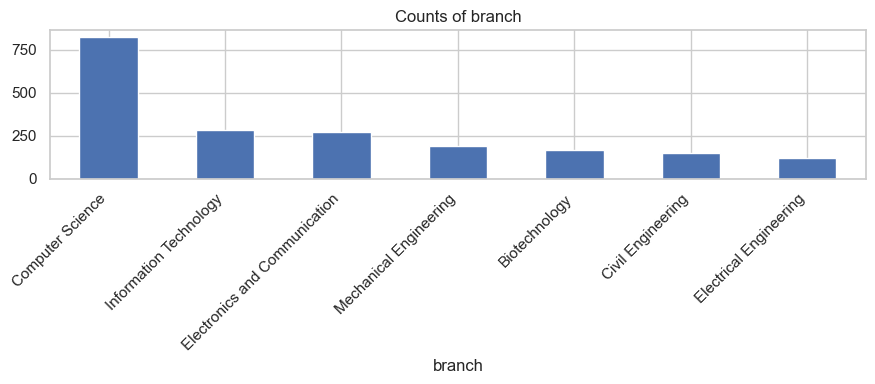

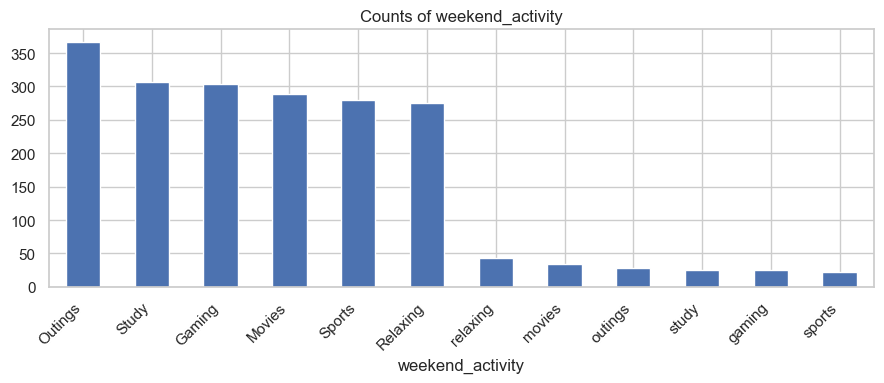

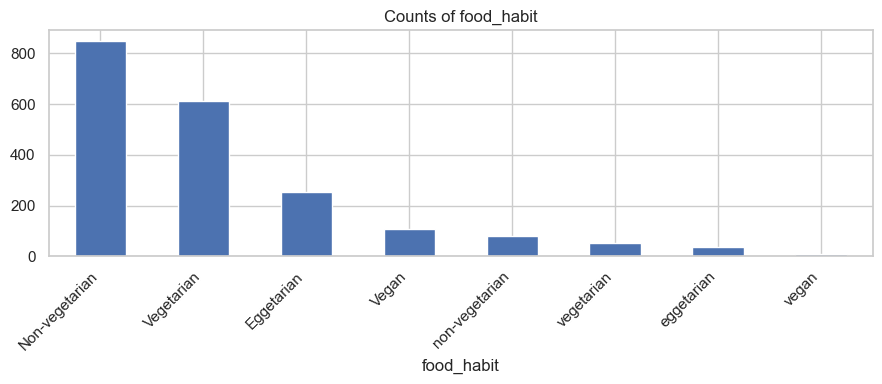

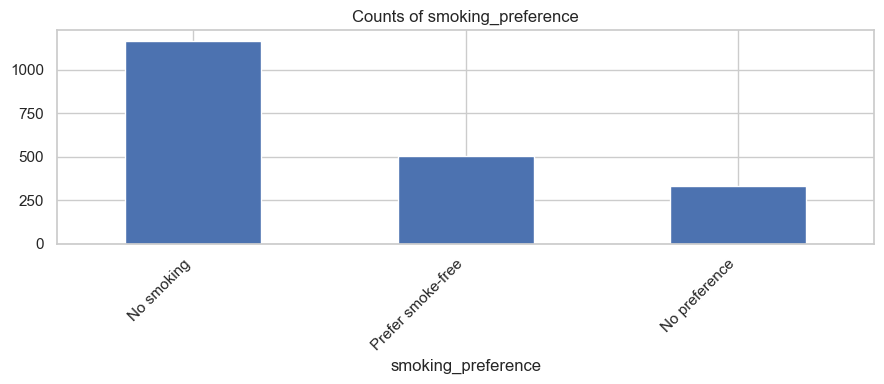

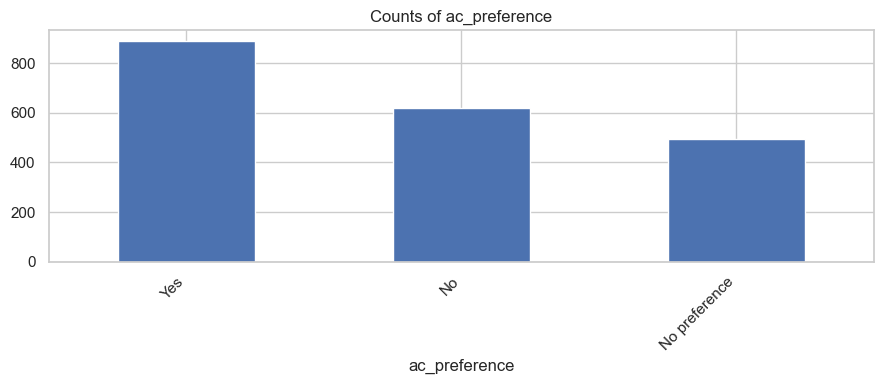

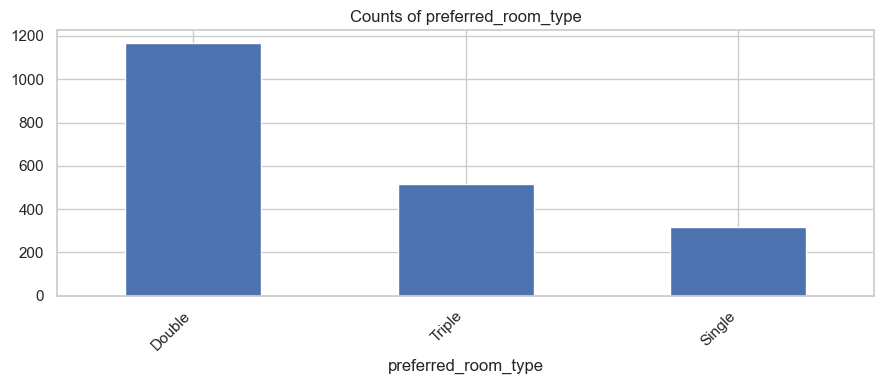

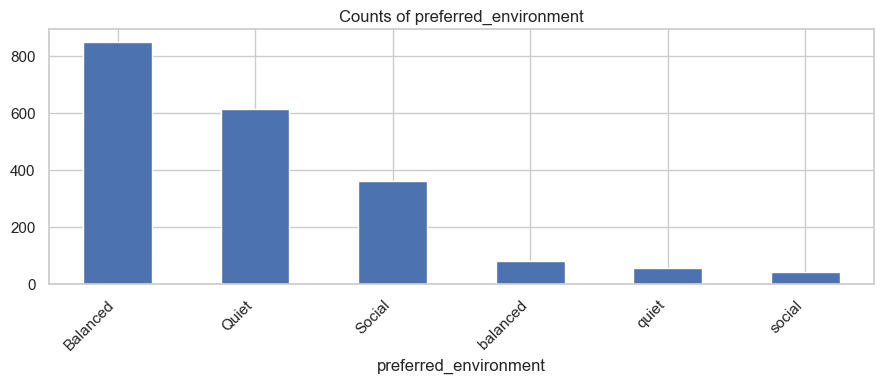

In [22]:
for col in categorical_cols:
    plt.figure(figsize=(9,4))
    df[col].value_counts().head(15).plot(kind="bar")
    plt.title(f"Counts of {col}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

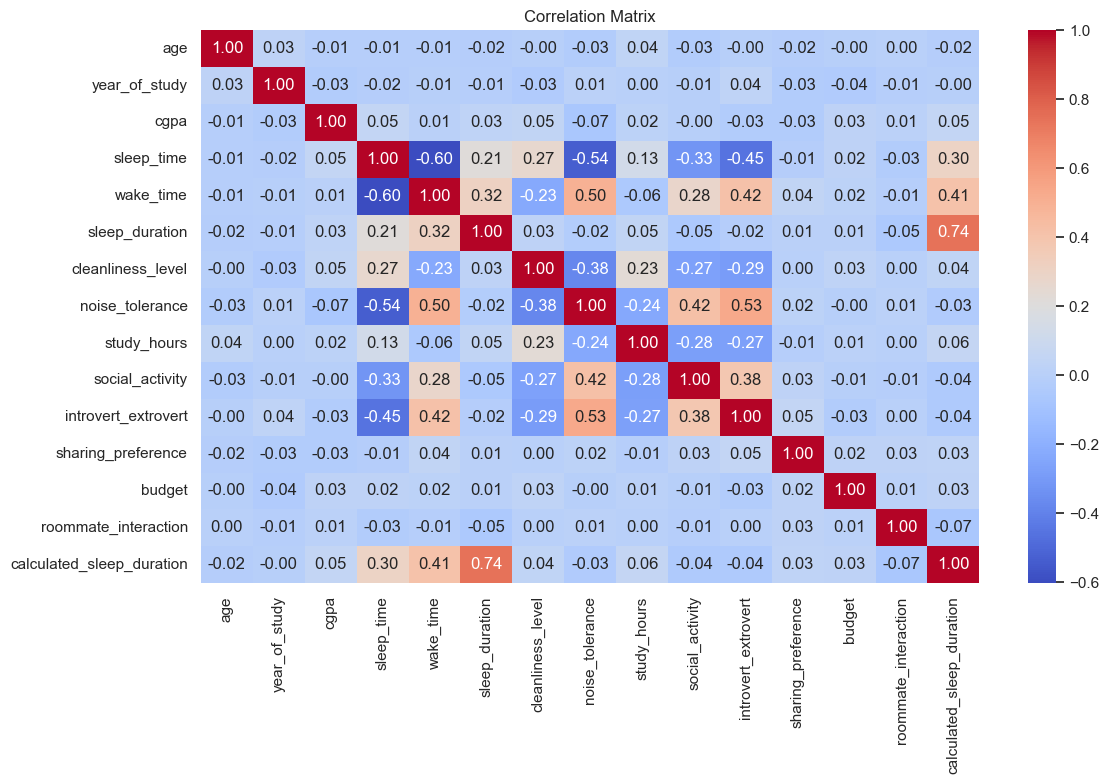

In [23]:
plt.figure(figsize=(12,8))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [24]:
for col in ["branch","year_of_study","preferred_room_type","preferred_environment","food_habit"]:
    if col in df.columns:
        print(df[col].value_counts(normalize=True).mul(100).round(2))

branch
Computer Science                 41.05
Information Technology           14.05
Electronics and Communication    13.55
Mechanical Engineering            9.45
Biotechnology                     8.45
Civil Engineering                 7.40
Electrical Engineering            6.05
Name: proportion, dtype: float64
year_of_study
1    27.85
2    27.75
3    25.35
4    19.05
Name: proportion, dtype: float64
preferred_room_type
Double    58.35
Triple    25.80
Single    15.85
Name: proportion, dtype: float64
preferred_environment
Balanced    42.45
Quiet       30.70
Social      18.05
balanced     4.00
quiet        2.75
social       2.05
Name: proportion, dtype: float64
food_habit
Non-vegetarian    42.40
Vegetarian        30.55
Eggetarian        12.70
Vegan              5.35
non-vegetarian     4.05
vegetarian         2.70
eggetarian         1.85
vegan              0.40
Name: proportion, dtype: float64


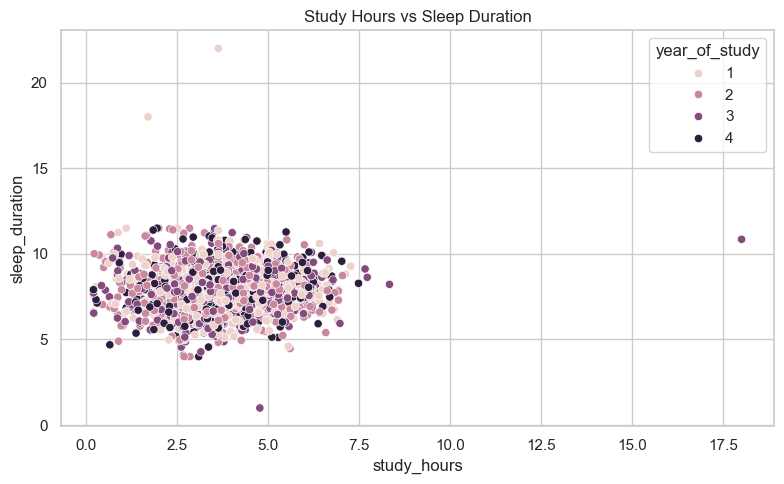

In [25]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="study_hours", y="sleep_duration", hue="year_of_study")
plt.title("Study Hours vs Sleep Duration")
plt.tight_layout()
plt.show()

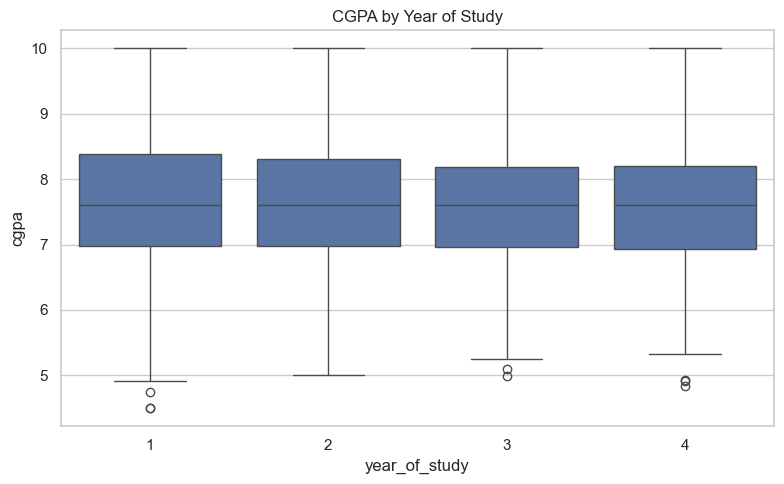

In [26]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="year_of_study", y="cgpa")
plt.title("CGPA by Year of Study")
plt.tight_layout()
plt.show()

In [27]:
pd.crosstab(df["cleanliness_level"], df["noise_tolerance"], normalize="index").round(3)

noise_tolerance,1.0,2.0,3.0,4.0,5.0
cleanliness_level,,,,,
1.0,0.000,0.016,0.238,0.381,0.365
2.0,0.013,0.050,0.208,0.346,0.384
3.0,0.126,0.189,0.272,0.196,0.217
4.0,0.227,0.254,0.261,0.133,0.125
5.0,0.317,0.304,0.199,0.103,0.077


In [28]:
pd.crosstab(df["social_activity"], df["preferred_environment"], normalize="index").round(3)

preferred_environment,Balanced,Quiet,Social,balanced,quiet,social
social_activity,,,,,,
1,0.390,0.348,0.171,0.043,0.032,0.016
2,0.404,0.302,0.189,0.040,0.037,0.028
3,0.441,0.300,0.185,0.025,0.030,0.019
4,0.420,0.315,0.178,0.043,0.027,0.017
5,0.443,0.291,0.173,0.059,0.013,0.021
